# 04 — Fold-safe 5-fold cross-validation (baseline table of record)

**Purpose.** Produce the project's *trustworthy* baseline numbers. Notebook 03 gave a quick single-split look; here every model is evaluated by 5-fold stratified cross-validation with **all learned preprocessing (MICE imputation, scaling, label encoding) refit inside each fold**, so no validation patient ever influences the preprocessing used on them. The 2,417 test patients are never loaded.

**Reads:** `../data/raw/dataset.xlsx` · **Writes:** `../results/cv5_*.csv`, `cv5_oof.npz`, `cv5_reliability_ext.png`, `environment.txt`

**Design**
* Preprocessing is **imported** from `src/preprocessing/cv_pipeline.py` (one implementation, proved identical to notebook 02's output); `load_cv_pool()` returns only the 9,668 training rows, so the test rows are never loaded here.
* Three feature sets are compared: `raw` (14), `ext` (19) and `ext_noflags` (17), to test whether the two `*_was_missing` flags earn their place (notebook 01b found no demonstrated link between missingness and disease).
* Out-of-fold (OOF) probabilities are saved for every configuration (calibration, McNemar's test, stacking, error analysis); calibration is reported as Brier score and Expected Calibration Error.
* Models are compared with a paired bootstrap interval on macro-F1 differences and McNemar's exact test, Holm-corrected, because single-split and even CV rankings that differ by ~0.003 are noise.
* The decision rule for the feature set is written down before the results (section 12).

**What this notebook can and cannot tell you.** With 5 folds and ~1,934 validation patients per fold, the fold-to-fold standard deviation of macro-F1 is about 0.005–0.009. Differences smaller than that are not reliable; that is exactly why section 11 exists.

## 0. Setup

**What this does:** imports libraries, makes `src/` importable, prints versions, and writes `results/environment.txt` (the exact package versions of this run — put it in the repo so results can be reproduced).

In [1]:
import sys, os, time, json, subprocess, warnings
sys.path.append('..')

import numpy as np
import pandas as pd
import scipy, sklearn, xgboost
from scipy.stats import binomtest
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score
from xgboost import XGBClassifier

from src.preprocessing.cv_pipeline import preprocess_fold, load_cv_pool, EXT_NO_FLAGS

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)
os.makedirs('../results', exist_ok=True)
with open('../results/environment.txt', 'w') as f:
    f.write(f"Python: {sys.version}\n\n")
    f.write(subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout)
print("Saved ../results/environment.txt")

Python 3.13.9 | pandas 3.0.5 | numpy 2.5.2 | scipy 1.18.1 | scikit-learn 1.9.0 | xgboost 3.4.1
Saved ../results/environment.txt


## 1. Load the CV pool and verify it is the right 9,668 rows

**What this does:** `load_cv_pool()` reads the raw Excel file, applies the same fixed encodings and the same stratified 80/20 split as notebook 02, and returns **only the 80% training pool**. Nothing is imputed or scaled yet — that happens inside each fold.

**Checks (all must pass):**
* shape is `(9668, 17)`;
* the row IDs are *identical, in identical order* to `data/processed/y_train.csv` written by notebook 02 — proving this is the same training set and the test set is the same untouched 2,417 rows;
* the raw gaps are still present (nothing was imputed yet).

In [2]:
pool = load_cv_pool("../data/raw/dataset.xlsx")
ref_idx = pd.read_csv('../data/processed/y_train.csv', index_col=0).index
assert pool.shape == (9668, 17), pool.shape
assert pool.index.equals(ref_idx), "CV pool differs from notebook 02's training set!"
assert pool['RF'].isna().sum() > 0
print("CV pool:", pool.shape, "- identical rows/order to notebook 02's training set")

y_global = LabelEncoder().fit_transform(pool['Disease'])     # labels only, nothing learned from features
classes = sorted(pool['Disease'].unique())
K = len(classes)
print("classes (encoded 0..6):", dict(enumerate(classes)))

CV pool: (9668, 17) - identical rows/order to notebook 02's training set
classes (encoded 0..6): {0: 'Ankylosing Spondylitis', 1: 'Normal', 2: 'Psoriatic Arthritis', 3: 'Reactive Arthritis', 4: 'Rheumatoid Arthritis', 5: "Sjögren's Syndrome", 6: 'Systemic Lupus Erythematosus'}


## 2. Define the 5 folds

**What this does:** `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` splits the 9,668 patients into 5 parts of ~1,934, each keeping the class proportions. Each part is used once for validation while the other four (7,734 patients) train — the same sizes as notebook 03's split. `random_state=42` fixes these folds for every later notebook (05–12), so all comparisons are paired on the same patients.

**Checks:** every patient appears in exactly one validation fold; every fold contains all 7 classes with proportions close to the overall ones.

In [3]:
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
folds = list(skf.split(pool, pool['Disease']))

cover = np.zeros(len(pool), int)
for tr, va in folds:
    cover[va] += 1
    assert set(tr).isdisjoint(va)
assert (cover == 1).all(), "some patient is not validated exactly once"

prop = pd.DataFrame({f'fold{i+1}': pool['Disease'].iloc[va].value_counts(normalize=True)
                     for i, (tr, va) in enumerate(folds)}).round(3)
prop['overall'] = pool['Disease'].value_counts(normalize=True).round(3)
print("fold sizes (train/val):", [(len(tr), len(va)) for tr, va in folds])
print(prop)

fold sizes (train/val): [(7734, 1934), (7734, 1934), (7734, 1934), (7735, 1933), (7735, 1933)]
                              fold1  fold2  fold3  fold4  fold5  overall
Disease                                                                 
Rheumatoid Arthritis          0.236  0.236  0.236  0.235  0.235    0.236
Ankylosing Spondylitis        0.176  0.176  0.176  0.176  0.176    0.176
Sjögren's Syndrome            0.154  0.153  0.153  0.153  0.154    0.153
Psoriatic Arthritis           0.147  0.147  0.147  0.148  0.147    0.147
Normal                        0.133  0.132  0.132  0.133  0.133    0.133
Systemic Lupus Erythematosus  0.112  0.112  0.112  0.112  0.112    0.112
Reactive Arthritis            0.043  0.043  0.043  0.042  0.042    0.043


## 3. Models and feature sets

**Feature sets (columns fed to each model)**

| Name | Columns | Meaning |
|---|---|---|
| `raw` | 14 | The original measurements only |
| `ext_noflags` | 17 | raw + 3 engineered features (ESR+CRP composite, C3/C4 ratio, autoantibody sum) |
| `ext` | 19 | `ext_noflags` + the two missingness flags (`RF_was_missing`, `Anti-CCP_was_missing`) |

Comparing the three isolates two questions: do the engineered features help (`ext_noflags` vs `raw`), and do the flags help on top (`ext` vs `ext_noflags`)?

**Models** — same settings as notebook 03 (no tuning yet; tuning is notebook 07, with nested CV). Class imbalance is handled by balanced class weights (`class_weight='balanced'`, or balanced per-row `sample_weight` for XGBoost and Gradient Boosting). Whether that is the best imbalance strategy is tested in notebook 05.

**Runtime:** about 10–20 minutes in total. Gradient Boosting is the slow part (~25–40 s per fit, 15 fits).

In [4]:
models = {
    'Logistic Regression': lambda: LogisticRegression(solver='lbfgs', class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest':       lambda: RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost':             lambda: XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, objective='multi:softprob', eval_metric='mlogloss', random_state=42, n_jobs=-1),
    'Gradient Boosting':   lambda: GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=3, random_state=42),
}
needs_sw = {'XGBoost', 'Gradient Boosting'}
feature_sets = ['raw', 'ext_noflags', 'ext']
print("configurations:", len(models) * len(feature_sets), "x", N_SPLITS, "folds =", len(models) * len(feature_sets) * N_SPLITS, "fits")

configurations: 12 x 5 folds = 60 fits


## 4. Metric helpers

**What this does:** defines the metrics used on the pooled out-of-fold (OOF) predictions — every patient's prediction made by a model that never saw that patient.

* **Fast macro-F1** — computed from the confusion matrix (also lets us bootstrap thousands of times quickly). Verified against scikit-learn in section 6.
* **Brier score (multiclass)** — mean over patients of Σ over classes (predicted probability − 1 if true class else 0)². Range 0 (perfect) to 2; lower is better. Punishes confident wrong answers.
* **Expected Calibration Error (ECE)** — group predictions by the model's top-class confidence (10 equal-width bins) and compare average confidence with actual accuracy in each bin; ECE is the size-weighted average gap. 0 = confidence matches reality; higher = over/under-confident.
* **McNemar's exact test** — for two models, among patients where exactly one is right, test whether they split 50/50. Tests *accuracy* differences, uses the exact binomial test (valid for any count).

**Caveat on calibration:** our models are trained with class weights that deliberately inflate minority-class probabilities, so their probabilities are *expected* to be miscalibrated for the real class mix. We report this honestly; notebook 05 revisits it.

In [5]:
def macro_f1_fast(y, p, k=K):
    cm = np.bincount(y * k + p, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    return np.mean(2 * tp / np.maximum(2 * tp + fp + fn, 1))

def brier_multiclass(y, P):
    return float(((P - np.eye(P.shape[1])[y]) ** 2).sum(1).mean())

def ece_top_label(y, P, bins=10):
    conf, pred = P.max(1), P.argmax(1); hit = (pred == y)
    edges = np.linspace(0, 1, bins + 1); ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(hit[m].mean() - conf[m].mean())
    return float(ece)

def mcnemar_exact(y, pa, pb):
    ca, cb = (pa == y), (pb == y)
    b, c = int((ca & ~cb).sum()), int((~ca & cb).sum())
    return b, c, (1.0 if b + c == 0 else binomtest(b, b + c, 0.5).pvalue)

def holm(p):
    p = np.asarray(p); m = len(p); order = np.argsort(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(order):
        run = max(run, min(1.0, (m - r) * p[i])); adj[i] = run
    return adj
print("helpers defined")

helpers defined


## 5. The cross-validation loop

**What this does, for each of the 5 folds**
1. `preprocess_fold(train_part, val_part)` fits the imputer, scalers and label encoder on the training part only and applies them to the validation part.
2. Builds the three feature sets by selecting columns.
3. Trains each of the 4 models on each feature set, predicts class probabilities for the validation patients, and records fold metrics (macro-F1, weighted-F1, accuracy, balanced accuracy, fit time).
4. Stores the probabilities in a patient-aligned array — after 5 folds every patient has exactly one out-of-fold prediction per configuration.

**Built-in checks per fold:** no missing values after preprocessing; the model's class order is 0–6; the fold's encoded labels equal the global encoding.

**What to watch:** one progress line per fold with its time.

In [6]:
keys = [f"{m}|{f}" for m in models for f in feature_sets]
oof_proba = {k: np.zeros((len(pool), K)) for k in keys}
y_all = np.full(len(pool), -1)
rows = []

for fold, (tr, va) in enumerate(folds, 1):
    t_fold = time.time()
    ft, fv = pool.iloc[tr], pool.iloc[va]
    Xr_tr, Xr_va, Xe_tr, Xe_va, y_tr, y_va = preprocess_fold(ft, fv)
    for Xd in (Xr_tr, Xr_va, Xe_tr, Xe_va):
        assert Xd.isna().sum().sum() == 0
    assert (y_va.to_numpy() == y_global[va]).all() and (y_tr.to_numpy() == y_global[tr]).all()
    y_all[va] = y_va.to_numpy()
    sw = compute_sample_weight('balanced', y_tr)
    sets = {'raw': (Xr_tr, Xr_va), 'ext': (Xe_tr, Xe_va),
            'ext_noflags': (Xe_tr[EXT_NO_FLAGS], Xe_va[EXT_NO_FLAGS])}
    for fname in feature_sets:
        Xt, Xv = sets[fname]
        for mname, make in models.items():
            model = make(); t0 = time.time()
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                model.fit(Xt, y_tr, sample_weight=sw) if mname in needs_sw else model.fit(Xt, y_tr)
            secs = time.time() - t0
            assert list(model.classes_) == list(range(K))
            proba = model.predict_proba(Xv); pred = proba.argmax(1)
            oof_proba[f"{mname}|{fname}"][va] = proba
            rows.append({'fold': fold, 'model': mname, 'features': fname,
                         'macro_f1': f1_score(y_va, pred, average='macro'),
                         'weighted_f1': f1_score(y_va, pred, average='weighted'),
                         'accuracy': accuracy_score(y_va, pred),
                         'balanced_accuracy': balanced_accuracy_score(y_va, pred),
                         'fit_seconds': secs})
    print(f"fold {fold}/{N_SPLITS} done in {time.time() - t_fold:.0f}s")

fold_df = pd.DataFrame(rows)
fold_df['key'] = fold_df['model'] + '|' + fold_df['features']
oof_pred = {k: v.argmax(1) for k, v in oof_proba.items()}
print("rows in fold table:", len(fold_df))

fold 1/5 done in 189s
fold 2/5 done in 418s
fold 3/5 done in 434s
fold 4/5 done in 217s
fold 5/5 done in 183s
rows in fold table: 60


## 6. Integrity checks on the out-of-fold predictions

**What this does**
* Every patient has exactly one validation label and every probability row sums to 1 (so nothing was left unfilled or double-filled).
* Recomputes one configuration's pooled macro-F1 with scikit-learn and with our fast function and requires them to match — proving the bootstrap machinery measures the same thing as the standard library.
* Shows that the **mean of the 5 fold scores** and the **pooled OOF score** are close (they differ slightly by construction: pooling weights every patient equally).

In [7]:
assert (y_all >= 0).all() and (y_all == y_global).all()
for k, P in oof_proba.items():
    assert np.allclose(P.sum(1), 1.0, atol=1e-6), k
k0 = 'Random Forest|ext'
a, b = f1_score(y_all, oof_pred[k0], average='macro'), macro_f1_fast(y_all, oof_pred[k0])
print(f"{k0}: sklearn pooled macro-F1 = {a:.6f} | fast = {b:.6f}")
assert abs(a - b) < 1e-9
print(f"{k0}: mean of fold scores = {fold_df[fold_df.key == k0].macro_f1.mean():.4f} | pooled OOF = {a:.4f}")
print("All integrity checks passed.")

Random Forest|ext: sklearn pooled macro-F1 = 0.817540 | fast = 0.817540
Random Forest|ext: mean of fold scores = 0.8175 | pooled OOF = 0.8175
All integrity checks passed.


## 7. The results table (with uncertainty)

**What this does:** one row per configuration.

* `macro_f1_mean ± std` — the average and spread of the 5 fold scores. **This is the main number.**
* `oof_macro_f1`, `ci_low`, `ci_high` — pooled out-of-fold macro-F1 with a 95% **bootstrap interval** (resample patients 2,000 times, recompute). Shows how uncertain the number is.
* `weighted_f1`, `accuracy`, `balanced_acc` — secondary metrics (accuracy is what many papers quote).
* `brier`, `ece` — calibration (lower is better).
* `fit_s` — average training time per fold.

**How to read it:** treat two configurations as different only if their bootstrap intervals barely overlap *and* section 11 confirms it. A gap of 0.003 is not a result.

In [8]:
rng = np.random.default_rng(42)
B = 2000
F = np.empty((B, len(keys)))
n = len(y_all)
for b in range(B):
    idx = rng.integers(0, n, n); yb = y_all[idx]
    for j, k in enumerate(keys):
        F[b, j] = macro_f1_fast(yb, oof_pred[k][idx])
kpos = {k: j for j, k in enumerate(keys)}

g = fold_df.groupby('key')
summary = pd.DataFrame({
    'model': [k.split('|')[0] for k in keys], 'features': [k.split('|')[1] for k in keys],
    'macro_f1_mean': [g.macro_f1.mean()[k] for k in keys], 'macro_f1_std': [g.macro_f1.std()[k] for k in keys],
    'oof_macro_f1': [macro_f1_fast(y_all, oof_pred[k]) for k in keys],
    'ci_low': [np.percentile(F[:, kpos[k]], 2.5) for k in keys], 'ci_high': [np.percentile(F[:, kpos[k]], 97.5) for k in keys],
    'weighted_f1': [g.weighted_f1.mean()[k] for k in keys], 'accuracy': [g.accuracy.mean()[k] for k in keys],
    'balanced_acc': [g.balanced_accuracy.mean()[k] for k in keys],
    'brier': [brier_multiclass(y_all, oof_proba[k]) for k in keys], 'ece': [ece_top_label(y_all, oof_proba[k]) for k in keys],
    'fit_s': [g.fit_seconds.mean()[k] for k in keys],
}, index=keys).sort_values('macro_f1_mean', ascending=False)
summary.round(4)

,model,features,macro_f1_mean,macro_f1_std,oof_macro_f1,ci_low,ci_high,weighted_f1,accuracy,balanced_acc,brier,ece,fit_s
Random Forest|ext,Random Forest,ext,0.8175,0.0081,0.8175,0.8091,0.8259,0.8287,0.8315,0.8278,0.2182,0.0359,2.4061
Gradient Boosting|ext_noflags,Gradient Boosting,ext_noflags,0.8161,0.0030,0.8161,0.8077,0.8241,0.8257,0.8266,0.8268,0.2303,0.0452,87.6053
Random Forest|ext_noflags,Random Forest,ext_noflags,0.8156,0.0083,0.8157,0.8073,0.8239,0.8264,0.8290,0.8258,0.2191,0.0277,2.8197
Gradient Boosting|ext,Gradient Boosting,ext,0.8148,0.0053,0.8148,0.8064,0.8231,0.8243,0.8252,0.8240,0.2263,0.0471,85.6763
XGBoost|ext,XGBoost,ext,0.8148,0.0046,0.8148,0.8063,0.8230,0.8238,0.8244,0.8213,0.2275,0.0605,4.5128
Random Forest|raw,Random Forest,raw,0.8145,0.0039,0.8145,0.8060,0.8227,0.8254,0.8293,0.8244,0.2234,0.0430,2.2012
XGBoost|raw,XGBoost,raw,0.8142,0.0038,0.8143,0.8058,0.8226,0.8227,0.8239,0.8183,0.2304,0.0580,5.8761
XGBoost|ext_noflags,XGBoost,ext_noflags,0.8109,0.0049,0.8109,0.8022,0.8194,0.8207,0.8217,0.8169,0.2312,0.0607,4.3751
Gradient Boosting|raw,Gradient Boosting,raw,0.8071,0.0027,0.8070,0.7985,0.8152,0.8180,0.8185,0.8192,0.2300,0.0533,87.6821
Logistic Regression|ext,Logistic Regression,ext,0.7902,0.0111,0.7902,0.7822,0.7985,0.8009,0.7986,0.8187,0.2733,0.0133,0.5475


## 8. Does this reproduce the cross-validation results of the starting pipeline?

**What this does:** if `results/cv_summary.csv` (the cross-validation results of the project's starting pipeline) is present, prints its mean macro-F1 next to ours for the same model and feature set. In the recorded run all six comparable configurations matched exactly (maximum difference 0.0000); that file is not part of this repository, in which case the cell reports that the comparison is skipped.

**What to expect when the file is present:** the same numbers, within about ±0.01 at most. A difference above 0.02 would mean something changed in the data or the pipeline and must be investigated before trusting this table.

In [9]:
ref_path = '../results/cv_summary.csv'
if os.path.exists(ref_path):
    old = pd.read_csv(ref_path, index_col=[0, 1])['macro_f1_mean']
    cmp_rows = []
    for (m, f), v in old.items():
        k = f"{m}|{f}"
        if k in summary.index:
            cmp_rows.append({'config': k, 'old_cv': v, 'new_cv': summary.loc[k, 'macro_f1_mean'],
                             'diff': summary.loc[k, 'macro_f1_mean'] - v})
    cmp_df = pd.DataFrame(cmp_rows).round(4)
    print(cmp_df.to_string(index=False))
    print("\nmax |diff|:", cmp_df['diff'].abs().max().round(4))
    if cmp_df['diff'].abs().max() > 0.02:
        print("WARNING: difference > 0.02 - investigate before trusting this table.")
else:
    print("No old cv_summary.csv found - skipping the reproduction comparison.")

                 config  old_cv  new_cv  diff
      Random Forest|ext  0.8175  0.8175   0.0
            XGBoost|ext  0.8148  0.8148   0.0
      Random Forest|raw  0.8145  0.8145  -0.0
            XGBoost|raw  0.8142  0.8142   0.0
Logistic Regression|ext  0.7902  0.7902  -0.0
Logistic Regression|raw  0.7868  0.7868  -0.0

max |diff|: 0.0


## 9. Which diseases fail? (best configuration, pooled out-of-fold)

**What this does:** takes the top configuration by mean fold macro-F1 and prints its per-class precision/recall/F1 and the five most common specific confusions, now over all 9,668 patients (so each class has far more evidence than in notebook 03; Reactive Arthritis has 516 patients instead of 83).

**Why:** the paper's contribution has to address the weak classes. In notebook 03 the weakest were Ankylosing Spondylitis (F1 ≈ 0.6) and Reactive Arthritis (≈ 0.6, precision lower than recall, i.e. over-prediction caused by class weighting). This section checks whether that holds with 5× more data.

In [10]:
from sklearn.metrics import classification_report, confusion_matrix
best_key = summary.index[0]
print("Best configuration by mean fold macro-F1:", best_key, "\n")
print(classification_report(y_all, oof_pred[best_key], target_names=classes, digits=3))
cm = confusion_matrix(y_all, oof_pred[best_key], labels=list(range(K)))
off = sorted([(cm[i, j], i, j) for i in range(K) for j in range(K) if i != j], reverse=True)
print("Top 5 confusions (true -> predicted):")
for cnt, i, j in off[:5]:
    print(f"  {classes[i]:<30} -> {classes[j]:<30} {cnt:>4} ({cnt / cm[i].sum():.1%} of true {classes[i]})")

Best configuration by mean fold macro-F1: Random Forest|ext 

                              precision    recall  f1-score   support

      Ankylosing Spondylitis      0.735     0.570     0.642      1702
                      Normal      0.882     0.826     0.853      1283
         Psoriatic Arthritis      0.852     0.891     0.871      1426
          Reactive Arthritis      0.558     0.729     0.632       413
        Rheumatoid Arthritis      0.816     0.888     0.850      2278
          Sjögren's Syndrome      0.860     0.917     0.888      1482
Systemic Lupus Erythematosus      0.999     0.973     0.986      1084

                    accuracy                          0.832      9668
                   macro avg      0.815     0.828     0.818      9668
                weighted avg      0.832     0.832     0.829      9668

Top 5 confusions (true -> predicted):
  Ankylosing Spondylitis         -> Rheumatoid Arthritis            395 (23.2% of true Ankylosing Spondylitis)
  Normal        

## 10. Calibration plot

**What this does:** a *reliability diagram* for the four models on the 19-feature set. Each point is a group of predictions with similar confidence; the x-axis is the model's average confidence, the y-axis is how often it was actually right. A perfectly calibrated model lies on the diagonal. Points below the diagonal mean over-confidence.

**Expect:** Logistic Regression and the boosted models to look different from Random Forest (forests tend to be under-confident; boosting tends to be over-confident). Remember that class weights distort all of them.

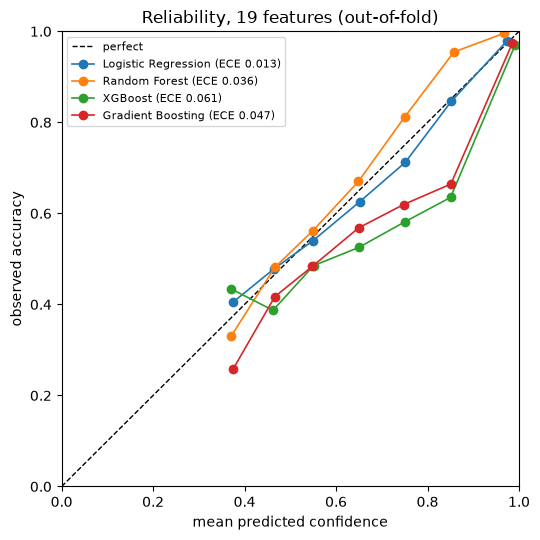

In [11]:
import matplotlib
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='perfect')
edges = np.linspace(0, 1, 11)
for m in models:
    P = oof_proba[f"{m}|ext"]; conf, hit = P.max(1), (P.argmax(1) == y_all)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        sel = (conf > lo) & (conf <= hi)
        if sel.sum() >= 20:
            xs.append(conf[sel].mean()); ys.append(hit[sel].mean())
    ax.plot(xs, ys, marker='o', lw=1.2, label=f"{m} (ECE {ece_top_label(y_all, P):.3f})")
ax.set_xlabel('mean predicted confidence'); ax.set_ylabel('observed accuracy')
ax.set_title('Reliability, 19 features (out-of-fold)'); ax.legend(fontsize=8); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig('../results/cv5_reliability_ext.png', dpi=150); plt.show()

## 11. Which differences are real? Paired comparisons

**What this does:** for each comparison of interest (A vs B) it reports four things, all on the *same* patients (paired):

| Column | Meaning |
|---|---|
| `fold_diff_mean`, `folds_A_better` | Average per-fold macro-F1 difference (A − B) and in how many of the 5 folds A beat B |
| `oof_diff` | Pooled out-of-fold macro-F1 difference (A − B) |
| `ci_low`, `ci_high` | 95% paired-bootstrap interval of that difference. **If it includes 0, the difference is not distinguishable from noise.** |
| `mcnemar_b/c`, `p_holm` | McNemar exact test on accuracy: b = patients only A got right, c = only B. `p_holm` is corrected for running all these tests together. |

**Comparisons**
* *Feature sets within each model:* `ext` vs `raw` (everything added), `ext_noflags` vs `raw` (3 engineered features), `ext` vs `ext_noflags` (the two flags).
* *Models on the 19-feature set:* all six pairs.

**Caveat (honest):** the pooled out-of-fold predictions come from five different models whose training sets overlap, so the observations are not fully independent and the McNemar p-values are somewhat optimistic. The bootstrap interval has the same weakness. Treat borderline results as borderline.

In [12]:
comps = []
for m in models:
    comps += [(f"{m}|ext", f"{m}|raw", f"{m}: ext vs raw (all additions)"),
              (f"{m}|ext_noflags", f"{m}|raw", f"{m}: 3 engineered features"),
              (f"{m}|ext", f"{m}|ext_noflags", f"{m}: 2 missingness flags")]
mn = list(models)
for i in range(len(mn)):
    for j in range(i + 1, len(mn)):
        comps.append((f"{mn[i]}|ext", f"{mn[j]}|ext", f"{mn[i]} vs {mn[j]} (ext)"))

piv = fold_df.pivot(index='fold', columns='key', values='macro_f1')
out = []
for A, Bk, label in comps:
    d = F[:, kpos[A]] - F[:, kpos[Bk]]
    bb, cc, p = mcnemar_exact(y_all, oof_pred[A], oof_pred[Bk])
    fd = piv[A] - piv[Bk]
    out.append({'comparison': label, 'fold_diff_mean': fd.mean(), 'folds_A_better': int((fd > 0).sum()),
                'oof_diff': macro_f1_fast(y_all, oof_pred[A]) - macro_f1_fast(y_all, oof_pred[Bk]),
                'ci_low': np.percentile(d, 2.5), 'ci_high': np.percentile(d, 97.5),
                'mcnemar_b': bb, 'mcnemar_c': cc, 'p_raw': p, 'A': A, 'B': Bk})
pairs = pd.DataFrame(out)
pairs['p_holm'] = holm(pairs['p_raw'])
pairs['CI_excludes_0'] = (pairs['ci_low'] > 0) | (pairs['ci_high'] < 0)
pairs.drop(columns=['A', 'B', 'p_raw']).round(4)

,comparison,fold_diff_mean,folds_A_better,oof_diff,ci_low,ci_high,mcnemar_b,mcnemar_c,p_holm,CI_excludes_0
0,Logistic Regression: ext vs raw (all additions),0.0034,4,0.0034,0.0001,0.0069,156,137,1.0000,True
1,Logistic Regression: 3 engineered features,0.0024,5,0.0024,0.0008,0.0042,39,23,0.6149,True
2,Logistic Regression: 2 missingness flags,0.0010,3,0.0011,-0.0022,0.0044,145,142,1.0000,False
3,Random Forest: ext vs raw (all additions),0.0030,4,0.0031,-0.0017,0.0077,226,205,1.0000,False
4,Random Forest: 3 engineered features,0.0011,2,0.0012,-0.0033,0.0056,201,204,1.0000,False
5,Random Forest: 2 missingness flags,0.0019,3,0.0019,-0.0022,0.0060,173,149,1.0000,False
6,XGBoost: ext vs raw (all additions),0.0006,2,0.0005,-0.0056,0.0066,351,346,1.0000,False
7,XGBoost: 3 engineered features,-0.0033,2,-0.0034,-0.0089,0.0023,303,324,1.0000,False
8,XGBoost: 2 missingness flags,0.0039,5,0.0039,-0.0010,0.0089,254,228,1.0000,False
9,Gradient Boosting: ext vs raw (all additions),0.0078,5,0.0078,0.0021,0.0136,374,309,0.1998,True


## 12. Pre-specified decision rule for the feature set (written before seeing the numbers)

**The rule.** For the best model of section 9 only (to avoid cherry-picking across four models):
* a feature group is **kept** only if (i) the 95% paired-bootstrap interval of its macro-F1 gain **excludes 0** *and* (ii) it wins in **at least 4 of the 5 folds**;
* otherwise the simpler set is preferred (`raw` < `ext_noflags` < `ext`).

**Mapping to the three comparisons**
* flags kept? → `ext` vs `ext_noflags`
* engineered features kept? → `ext_noflags` vs `raw`
* recommended set: `ext` if the flags are kept; else `ext_noflags` if the engineered features are kept; else `raw`. (If neither group passes alone but `ext` vs `raw` passes jointly, `ext` is recommended and flagged as a joint-only gain.)

**Status of the outcome:** this is a *candidate* to carry into notebook 06 (feature selection), not a final choice. The other three models' results are printed for consistency — if they point the opposite way, that is itself a finding to report.

In [13]:
def verdict(A, Bk):
    r = pairs[(pairs.A == A) & (pairs.B == Bk)].iloc[0]
    keep = bool(r['CI_excludes_0'] and r['ci_low'] > 0 and r['folds_A_better'] >= 4)
    return keep, r

bm = best_key.split('|')[0]
flags_keep, r_flags = verdict(f"{bm}|ext", f"{bm}|ext_noflags")
eng_keep,   r_eng   = verdict(f"{bm}|ext_noflags", f"{bm}|raw")
joint_keep, r_joint = verdict(f"{bm}|ext", f"{bm}|raw")
if flags_keep:   rec = 'ext'
elif eng_keep:   rec = 'ext_noflags'
elif joint_keep: rec = 'ext (joint gain only)'
else:            rec = 'raw'

print(f"Decision model: {bm}")
for name, keep, r in (('missingness flags', flags_keep, r_flags), ('engineered features', eng_keep, r_eng), ('all additions (joint)', joint_keep, r_joint)):
    print(f"  {name:<22} gain {r['oof_diff']:+.4f}  CI [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]  folds better {r['folds_A_better']}/5  -> {'KEEP' if keep else 'not shown to help'}")
print("\nRecommended feature set to carry forward:", rec)

print("\nSame three comparisons for the other models (consistency check):")
for m in models:
    if m == bm: continue
    for nm, (A, Bk) in (('flags', (f"{m}|ext", f"{m}|ext_noflags")), ('engineered', (f"{m}|ext_noflags", f"{m}|raw"))):
        r = pairs[(pairs.A == A) & (pairs.B == Bk)].iloc[0]
        print(f"  {m:<20} {nm:<11} gain {r['oof_diff']:+.4f}  CI [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]  folds {r['folds_A_better']}/5")

Decision model: Random Forest
  missingness flags      gain +0.0019  CI [-0.0022, +0.0060]  folds better 3/5  -> not shown to help
  engineered features    gain +0.0012  CI [-0.0033, +0.0056]  folds better 2/5  -> not shown to help
  all additions (joint)  gain +0.0031  CI [-0.0017, +0.0077]  folds better 4/5  -> not shown to help

Recommended feature set to carry forward: raw

Same three comparisons for the other models (consistency check):
  Logistic Regression  flags       gain +0.0011  CI [-0.0022, +0.0044]  folds 3/5
  Logistic Regression  engineered  gain +0.0024  CI [+0.0008, +0.0042]  folds 5/5
  XGBoost              flags       gain +0.0039  CI [-0.0010, +0.0089]  folds 5/5
  XGBoost              engineered  gain -0.0034  CI [-0.0089, +0.0023]  folds 2/5
  Gradient Boosting    flags       gain -0.0013  CI [-0.0060, +0.0032]  folds 2/5
  Gradient Boosting    engineered  gain +0.0091  CI [+0.0038, +0.0144]  folds 5/5


## 13. Save the results

**What this does:** writes everything needed by later notebooks and for the paper's tables.

| File | Content |
|---|---|
| `cv5_fold_scores.csv` | every (fold, model, feature set) score |
| `cv5_summary.csv` | the section-7 table |
| `cv5_pairwise_tests.csv` | the section-11 table |
| `cv5_oof.npz` | out-of-fold probabilities for every configuration + true labels (used later for stacking and error analysis) |

In [14]:
fold_df.drop(columns=['key']).to_csv('../results/cv5_fold_scores.csv', index=False)
summary.to_csv('../results/cv5_summary.csv')
pairs.drop(columns=['A', 'B']).to_csv('../results/cv5_pairwise_tests.csv', index=False)
np.savez_compressed('../results/cv5_oof.npz', y=y_all, classes=np.array(classes),
                    **{k.replace('|', '__').replace(' ', '_'): v.astype(np.float32) for k, v in oof_proba.items()})
print(sorted(f for f in os.listdir('../results') if f.startswith('cv5_')))

['cv5_fold_scores.csv', 'cv5_oof.npz', 'cv5_pairwise_tests.csv', 'cv5_reliability_ext.png', 'cv5_summary.csv']


## Summary — what this notebook establishes

* The project's baseline table of record: 4 models × 3 feature sets, fold-safe 5-fold CV, with bootstrap uncertainty and calibration.
* A statistically-grounded answer to: do the engineered features and the two missingness flags help?
* A candidate feature set for notebook 06 and the out-of-fold probabilities for notebook 08 (stacking).
* **Not established:** a final model. Hyperparameters are untuned and imbalance handling is not yet compared (notebooks 05 and 07).